# 학습

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sachinpatel21/az-handwritten-alphabets-in-csv-format")

print("Path to dataset files:", path)

100%|██████████| 185M/185M [00:00<00:00, 245MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sachinpatel21/az-handwritten-alphabets-in-csv-format/versions/5


In [2]:
import os
import pandas as pd

print("다운로드된 데이터셋 디렉토리 내용:")
for file in os.listdir(path):
  print(file)

data_file_path = os.path.join(path, 'A_Z Handwritten Data.csv')
df = pd.read_csv(data_file_path)
print("데이터 로드 완료! 데이터 헤드:")
print(df.head())

다운로드된 데이터셋 디렉토리 내용:
A_Z Handwritten Data.csv
A_Z Handwritten Data
데이터 로드 완료! 데이터 헤드:
   0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  ...  0.639  0.640  0.641  \
0  0    0    0    0    0    0    0    0    0    0  ...      0      0      0   
1  0    0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  0    0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  0    0    0    0    0    0    0    0    0    0  ...      0      0      0   
4  0    0    0    0    0    0    0    0    0    0  ...      0      0      0   

   0.642  0.643  0.644  0.645  0.646  0.647  0.648  
0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0  

[5 rows x 785 columns]


In [3]:
first_image_pixels = df.iloc[0, 1:]

print("첫 번째 이미지 픽셀 데이터 (일부):")
print(first_image_pixels.head())

첫 번째 이미지 픽셀 데이터 (일부):
0.1    0
0.2    0
0.3    0
0.4    0
0.5    0
Name: 0, dtype: int64


In [4]:
alphabets = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

char_to_label = {char: i for i, char in enumerate(alphabets)}
label_to_char = {i: char for i, char in enumerate(alphabets)}

label_counts_with_alphabets = df.iloc[:, 0].value_counts().sort_index().rename(index=label_to_char)

print("알파벳 라벨별 개수 (알파벳으로 표시):")
print(label_counts_with_alphabets)

알파벳 라벨별 개수 (알파벳으로 표시):
0
A    13869
B     8668
C    23409
D    10134
E    11440
F     1163
G     5762
H     7218
I     1120
J     8493
K     5603
L    11586
M    12336
N    19010
O    57825
P    19341
Q     5812
R    11566
S    48419
T    22495
U    29008
V     4182
W    10784
X     6272
Y    10859
Z     6076
Name: count, dtype: int64


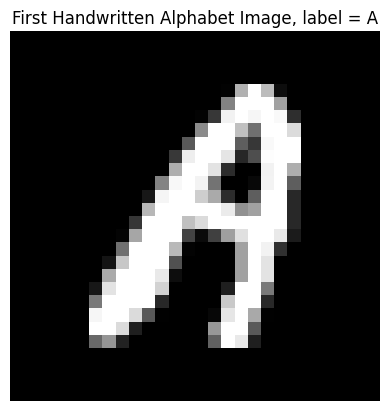

In [5]:
import matplotlib.pyplot as plt
import numpy as np

plt.imshow(first_image_pixels.values.reshape(28, 28), cmap='gray')
plt.title(f"First Handwritten Alphabet Image, label = {label_to_char[df.iloc[0, 0]]}")
plt.axis('off')
plt.show()

알파벳 라벨별 개수:
0
0     13869
1      8668
2     23409
3     10134
4     11440
5      1163
6      5762
7      7218
8      1120
9      8493
10     5603
11    11586
12    12336
13    19010
14    57825
15    19341
16     5812
17    11566
18    48419
19    22495
20    29008
21     4182
22    10784
23     6272
24    10859
25     6076
Name: count, dtype: int64


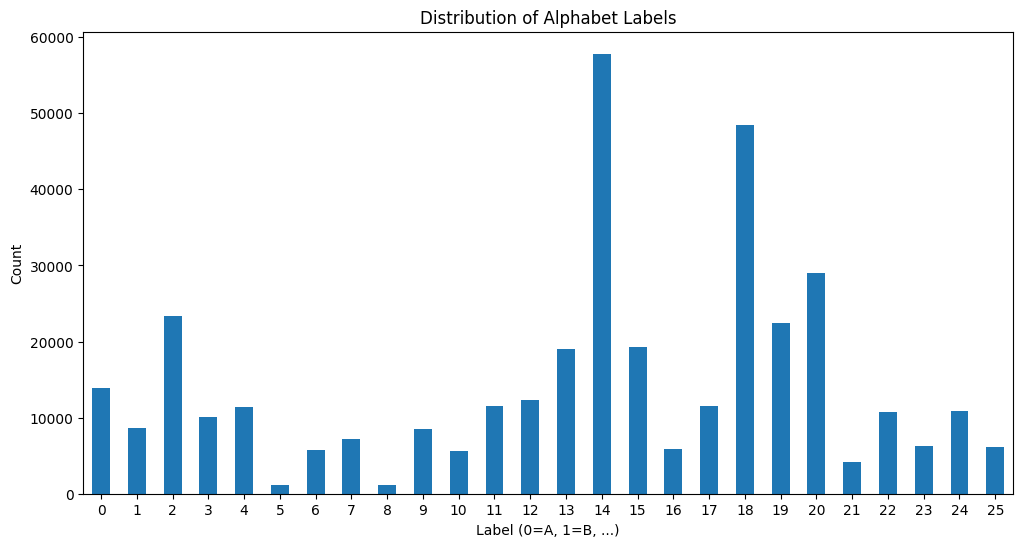

In [6]:
label_counts = df.iloc[:, 0].value_counts().sort_index()

print("알파벳 라벨별 개수:")
print(label_counts)

plt.figure(figsize=(12, 6))
label_counts.plot(kind='bar')
plt.title('Distribution of Alphabet Labels')
plt.xlabel('Label (0=A, 1=B, ...)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader

In [8]:
batch_size = 128
latent_dim = 20
num_classes = 26
epochs = 50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [9]:
import numpy as np
from torch.utils.data import Dataset, DataLoader

class HandwrittenAlphabetDataset(Dataset):
  def __init__(self, dataframe, transform=None):
    # 첫 번째 열은 라벨, 나머지 열은 픽셀 데이터
    self.labels = dataframe.iloc[:, 0].values
    self.images = dataframe.iloc[:, 1:].values.astype(np.float32) / 255.0
    self.transform = transform

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    image = self.images[idx].reshape(28, 28, 1)
    label = self.labels[idx]

    if self.transform:
      image = self.transform(image)

    return image, label

In [10]:
transform = transforms.ToTensor()

train_dataset = HandwrittenAlphabetDataset(df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

print(f"Total number of samples in dataset: {len(train_dataset)}")
print(f"Number of batches in train_loader: {len(train_loader)}")

Total number of samples in dataset: 372450
Number of batches in train_loader: 2910


In [11]:
images, labels = next(iter(train_loader))

print(f"Shape of images in a batch: {images.shape}")
print(f"Shape of labels in a batch: {labels.shape}")

Shape of images in a batch: torch.Size([128, 1, 28, 28])
Shape of labels in a batch: torch.Size([128])


In [4]:
class CVAE(nn.Module):
  def __init__(self, latent_dim = 20, num_classes = 26):
    super(CVAE, self).__init__()
    self.encoder = nn.Sequential(
        nn.Linear(784 + num_classes, 512),
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.ReLU(),
    )
    self.mu = nn.Linear(256, latent_dim)
    self.logvar = nn.Linear(256, latent_dim)
    self.decoder = nn.Sequential(
        nn.Linear(latent_dim + num_classes, 256),
        nn.ReLU(),
        nn.Linear(256, 512),
        nn.ReLU(),
        nn.Linear(512, 784),
        nn.Sigmoid()
    )

  def encode(self, x, c):
    x = x.view(-1, 784)
    combined_input = torch.cat([x, c], dim=1)
    h = self.encoder(combined_input)
    mu = self.mu(h)
    logvar = self.logvar(h)
    return mu, logvar

  def reparameterize(self, mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + eps * std

  def decode(self, z, c):
    c_onehot = c
    combined_input = torch.cat([z, c_onehot], dim=1)
    return self.decoder(combined_input)

  def forward(self, x, c):
    mu, logvar = self.encode(x, c)
    z = self.reparameterize(mu, logvar)
    return self.decode(z, c), mu, logvar

In [13]:
def loss_function(recon_x, x, mu, logvar):
  BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')
  KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
  return BCE + KLD

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

def plot_conditional_generation(model, latent_dim, num_classes=26, num_z=5):
    model.eval()

    fig, axes = plt.subplots(num_z, num_classes, figsize=(0.4 * num_classes, 0.4 * num_z))

    with torch.no_grad():
      for row in range(num_z):
        z_sample = torch.randn(1, latent_dim).to(device)

        for col in range(num_classes):
          target_label = torch.tensor([col]).to(device)
          y_sample = F.one_hot(target_label, num_classes=num_classes).float()

          generated_img = model.decode(z_sample, y_sample)
          generated_img = generated_img.view(28, 28).cpu().numpy()

          axes[row, col].imshow(generated_img, cmap='gray')
          axes[row, col].axis('off')

          axes[row, col].set_aspect('equal')

          if row == 0:
            axes[row, col].set_title(label_to_char[col], fontsize=8)

    plt.subplots_adjust(wspace=0.0, hspace=0.0)
    plt.show()

1 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

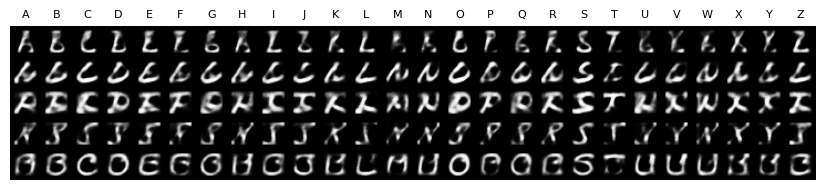

2 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

3 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

4 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

5 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

6 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

7 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

8 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

9 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

10 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

11 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

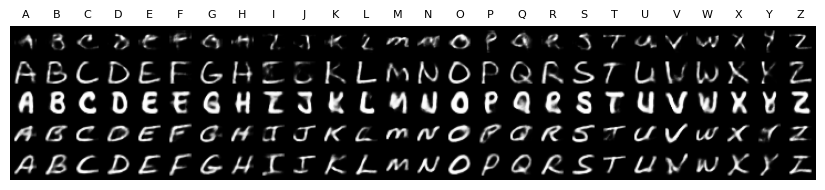

12 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

13 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

14 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

15 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

16 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

17 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

18 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

19 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

20 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

21 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

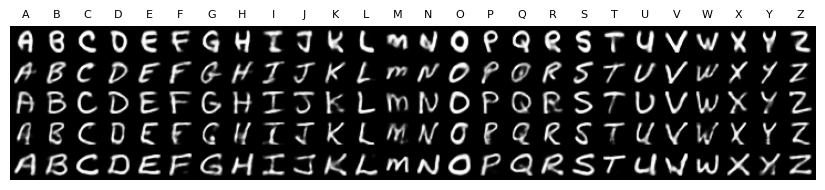

22 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

23 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

24 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

25 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

26 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

27 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

28 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

29 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

30 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

31 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

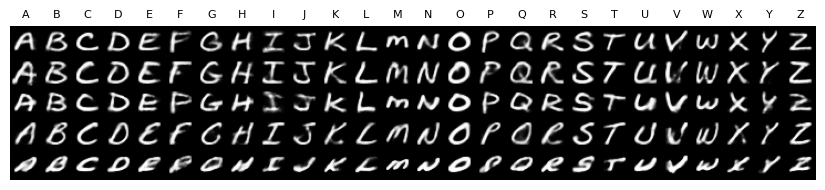

32 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

33 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

34 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

35 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

36 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

37 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

38 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

39 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

40 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

41 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

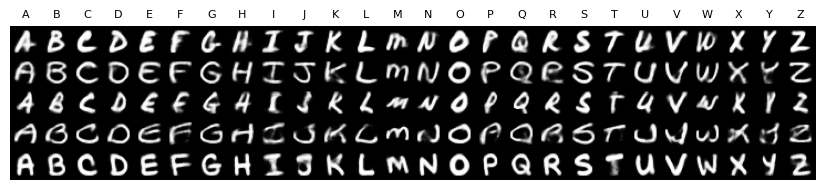

42 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

43 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

44 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

45 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

46 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

47 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

48 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

49 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

50 / 50:   0%|          | 0/2910 [00:00<?, ?it/s]

In [15]:
from tqdm.notebook import tqdm

model = CVAE(latent_dim=latent_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)


for epoch in range(epochs):
  model.train()
  train_loss = 0
  pbar = tqdm(train_loader, desc=f"{epoch+1} / {epochs}")
  for data, labels in pbar:
    data = data.to(device)

    y_one_hot = F.one_hot(labels.long(), num_classes=num_classes).float().to(device)

    optimizer.zero_grad()
    recon_batch, mu, logvar = model(data, y_one_hot)

    loss = loss_function(recon_batch, data, mu, logvar)
    loss.backward()
    train_loss += loss.item()
    optimizer.step()

    pbar.set_postfix(loss=f"{loss.item():.2f}")
  if epoch % 10 == 0:
    plot_conditional_generation(model, latent_dim, num_classes)

# 저장 및 불러오기

In [16]:
torch.save(model.state_dict(), "CVAE.pth")

In [8]:
latent_dim = 20
num_classes = 26
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

model = CVAE(latent_dim=latent_dim).to(device)
model.load_state_dict(torch.load('CVAE.pth', map_location=torch.device('cpu')))
model.to(torch.device('cpu')) # Ensure the model itself is on CPU

cpu


CVAE(
  (encoder): Sequential(
    (0): Linear(in_features=810, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (mu): Linear(in_features=256, out_features=20, bias=True)
  (logvar): Linear(in_features=256, out_features=20, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=46, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [1]:
import torch
import csv
import os

def export_entry_ultimate_clean_csv(pth_path, output_dir='entry_final_csv'):
  state_dict = torch.load(pth_path, map_location='cpu')

  if not os.path.exists(output_dir):
    os.makedirs(output_dir)

  layer_mapping = {
	'decoder.0': 'layer1',
	'decoder.2': 'layer2',
	'decoder.4': 'layer3'
  }

  for pth_name, entry_name in layer_mapping.items():
    weight = state_dict[f'{pth_name}.weight'].numpy()
    bias = state_dict[f'{pth_name}.bias'].numpy()
    num_nodes = len(weight)

    w_rows = []
    for i in range(num_nodes):
      row_str = ""
      for w_idx, w in enumerate(weight[i]):
        row_str += f"<w{w_idx+1}>{round(float(w), 5)}"
      row_str += "<빈공간>"
      w_rows.append([row_str])

    with open(f'{output_dir}/w_{entry_name}.csv', 'w', newline='', encoding='utf-8') as f:
      writer = csv.writer(f)
      writer.writerows(w_rows)

    b_rows = []
    for i in range(num_nodes):
      b_val = round(float(bias[i]), 5)
      b_rows.append([str(b_val)])

    with open(f'{output_dir}/b_{entry_name}.csv', 'w', newline='', encoding='utf-8') as f:
      writer = csv.writer(f)
      writer.writerows(b_rows)

export_entry_ultimate_clean_csv('CVAE.pth')

# 손글씨 만들기

In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

model = CVAE(latent_dim=20, num_classes=26).to(device)
model.load_state_dict(torch.load("CVAE.pth", map_location=device))
model.eval()

char_to_idx = {
	chr(ord('a') + i): i
	for i in range(26)
}

def text_to_indices(text):
	indices = []

	for ch in text.lower():
		if ch in char_to_idx:
			indices.append(char_to_idx[ch])
		elif ch == " ":
			indices.append(None)

	return indices

def generate_letter(idx):
	z = torch.randn(1, 20).to(device)

	c = F.one_hot(
		torch.tensor([idx], device=device),
		num_classes=26
	).float()

	with torch.no_grad():
		img = model.decode(z, c)

	return img.view(28, 28).cpu().numpy()

def generate(text = "Hello world"):
  indices = text_to_indices(text)

  fig, axes = plt.subplots(1, len(indices), figsize=(len(indices) * 1.5, 2))

  for ax, idx in zip(axes, indices):

    ax.axis("off")

    if idx is None:
      continue

    img = generate_letter(idx)

    ax.imshow(img, cmap="gray")

  plt.tight_layout()
  plt.show()

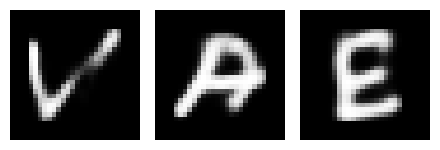

In [44]:
generate("VAE")